In [ ]:
"""
📊 Semana 13: Diseño de Dashboard de Control de Producción
Asignatura: Ciencia de Datos
Periodo: 2026-B

===================================================================
📝 REQUISITOS Y DEFINICIONES DEL DASHBOARD (PROCESO INDUSTRIAL)
===================================================================

1. Elección del Proceso y Definición de 3 KPIs:
-------------------------------------------------------------------
Para este ejercicio se ha seleccionado el Proceso de Producción Industrial,
enfocándome en el monitoreo de líneas de ensamblaje para la toma de decisiones gerenciales.

* OEE (Overall Equipment Effectiveness / Eficiencia General de los Equipos):
  - Objetivo: Medir la eficiencia global combinando disponibilidad, rendimiento y calidad.
  - Meta: > 85%

* Tasa de Producto Conforme (First Pass Yield - FPY):
  - Objetivo: Controlar el porcentaje de unidades fabricadas libres de defectos en el primer intento.
  - Meta: >= 96%

* Desviación del Programa de Producción (Cumplimiento de Plan):
  - Objetivo: Monitorear la variación porcentual entre las unidades planificadas y las reales entregadas.
  - Meta: +/- 2% máx.

-------------------------------------------------------------------
2. Boceto del Dashboard (Gráficos y Filtros):
-------------------------------------------------------------------

Filtros Globales del Tablero:
* Filtro de Fecha: Rango dinámico (Turno, Día, Semana, Mes).
* Filtro de Planta: Selector de Sede (Planta Neiva / Planta Pitalito).
* Filtro de Producto: Línea de ensamblaje o referencia específica.

Componentes Visuales del Boceto:
1. KPI Cards (Parte Superior): Tarjetas numéricas con valores actuales de OEE, FPY y Cumplimiento de Plan,
   acompañadas de alertas de color semafóricas automáticas.
2. Gráfico de Líneas (Centro-Izquierda): Comportamiento temporal y tendencia del OEE por hora o día.
3. Gráfico de Barras (Centro-Derecha): Producción Real frente a la Planificada por cada línea de producto.
4. Gráfico de Pareto (Parte Inferior): Análisis de causas principales de paradas de máquina o defectos de calidad.

-------------------------------------------------------------------
3. Justificación de la Jerarquía Visual:
-------------------------------------------------------------------

El diseño del tablero implementa una estructura clásica de pirámide invertida:
1. Nivel Superior (KPI Cards): Se posicionan primero para ofrecer una visión ejecutiva inmediata
   del estado general de la planta en menos de 3 segundos.
2. Nivel Intermedio (Tendencias y Comparativas): Ubicados en el centro para permitir al supervisor
   contextualizar cuándo y dónde ocurrieron las desviaciones operativas detectadas arriba.
3. Nivel Inferior (Análisis Causal - Pareto): Colocado al fondo para proporcionar a los ingenieros
   y analistas los detalles profundos necesarios para la toma de decisiones correctivas.
"""
print ("rta en el proximo bloque")

rta en el proximo bloque


In [ ]:
import numpy as np
import pandas as pd

# Configuración de reproducibilidad
np.random.seed(42)

# Días de análisis operacionales
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']
num_dias = len(dias)

# 1. Simulación de variables para OEE (Disponibilidad x Rendimiento x Calidad)
disponibilidad = np.random.uniform(0.90, 0.98, size=num_dias)
rendimiento = np.random.uniform(0.92, 0.97, size=num_dias)
calidad = np.random.uniform(0.95, 0.99, size=num_dias)
OEE_calculado = disponibilidad * rendimiento * calidad * 100

# 2. Simulación de variables para FPY (Tasa de Producto Conforme)
unidades_producidas = np.random.randint(1000, 1500, size=num_dias)
defectuosos_primer_intento = np.random.randint(15, 50, size=num_dias)
FPY_calculado = ((unidades_producidas - defectuosos_primer_intento) / unidades_producidas) * 100

# 3. Simulación de Desviación del Programa de Producción (Cumplimiento de Plan)
unidades_planificadas = np.random.randint(1100, 1400, size=num_dias)
cumplimiento_plan = (unidades_producidas / unidades_planificadas) * 100
desviacion_plan = cumplimiento_plan - 100

# Estructuración de los resultados en un DataFrame
df_kpis = pd.DataFrame({
    'Día': dias,
    'Disponibilidad (%)': disponibilidad * 100,
    'Rendimiento (%)': rendimiento * 100,
    'Calidad (%)': calidad * 100,
    'OEE (%)': OEE_calculado,
    'FPY (%)': FPY_calculado,
    'Cumplimiento Plan (%)': cumplimiento_plan,
    'Desviación Plan (%)': desviacion_plan
})

print("--- Cálculo de KPIs de Control de Producción ---")
display(df_kpis.round(2))

--- Cálculo de KPIs de Control de Producción ---


,Día,Disponibilidad (%),Rendimiento (%),Calidad (%),OEE (%),FPY (%),Cumplimiento Plan (%),Desviación Plan (%)
0,Lunes,93.00,92.29,98.33,84.39,96.60,97.55,-2.45
1,Martes,97.61,96.33,95.85,90.12,97.77,97.89,-2.11
2,Miércoles,95.86,95.01,95.73,87.18,97.23,88.22,-11.78
3,Jueves,94.79,95.54,95.73,86.70,98.85,132.43,32.43
4,Viernes,91.25,92.10,96.22,80.86,98.02,78.90,-21.10
5,Sábado,91.25,96.85,97.10,85.81,97.01,85.70,-14.30


### 4. Generación Visual del Boceto del Dashboard (Control de Producción)

/tmp/ipykernel_698/1530607005.py:115: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


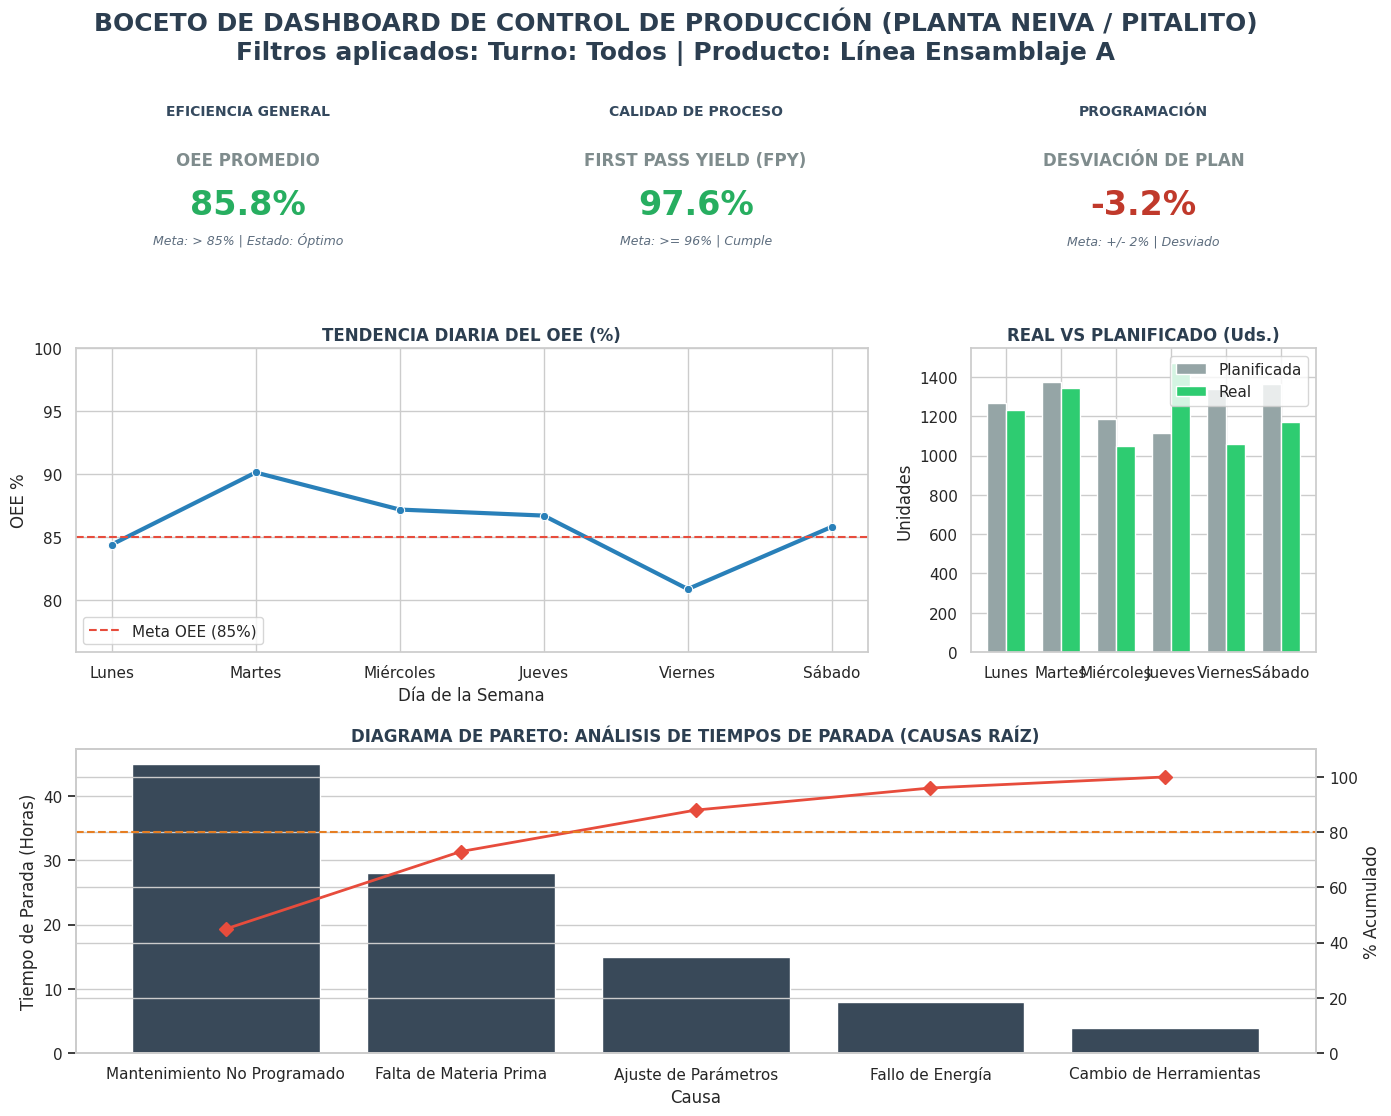

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Regenerar los datos para garantizar que la celda sea autocontenida
np.random.seed(42)
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']
num_dias = len(dias)

disponibilidad = np.random.uniform(0.90, 0.98, size=num_dias)
rendimiento = np.random.uniform(0.92, 0.97, size=num_dias)
calidad = np.random.uniform(0.95, 0.99, size=num_dias)
OEE_calculado = disponibilidad * rendimiento * calidad * 100

unidades_producidas = np.random.randint(1000, 1500, size=num_dias)
defectuosos_primer_intento = np.random.randint(15, 50, size=num_dias)
FPY_calculado = ((unidades_producidas - defectuosos_primer_intento) / unidades_producidas) * 100

unidades_planificadas = np.random.randint(1100, 1400, size=num_dias)
cumplimiento_plan = (unidades_producidas / unidades_planificadas) * 100
desviacion_plan = cumplimiento_plan - 100

df_kpis = pd.DataFrame({
    'Día': dias,
    'Disponibilidad (%)': disponibilidad * 100,
    'Rendimiento (%)': rendimiento * 100,
    'Calidad (%)': calidad * 100,
    'OEE (%)': OEE_calculado,
    'FPY (%)': FPY_calculado,
    'Cumplimiento Plan (%)': cumplimiento_plan,
    'Desviación Plan (%)': desviacion_plan
})

# 2. Configuración y Renderizado del Dashboard
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(16, 12))
fig.suptitle('BOCETO DE DASHBOARD DE CONTROL DE PRODUCCIÓN (PLANTA NEIVA / PITALITO)\nFiltros aplicados: Turno: Todos | Producto: Línea Ensamblaje A', fontsize=18, fontweight='bold', color='#2c3e50')

# Definición de la estructura de subplots (Grid de 3 filas)
gs = fig.add_gridspec(3, 3, height_ratios=[1, 2.5, 2.5], hspace=0.4, wspace=0.3)

# --- VALORES PROMEDIO PARA KPI CARDS ---
oee_mean = df_kpis['OEE (%)'].mean()
fpy_mean = df_kpis['FPY (%)'].mean()
desv_mean = df_kpis['Desviación Plan (%)'].mean()

# 1. KPI CARD - OEE (Meta > 85%)
ax_kpi1 = fig.add_subplot(gs[0, 0])
ax_kpi1.axis('off')
oee_color = '#27ae60' if oee_mean > 85 else '#c0392b'
ax_kpi1.patch.set_facecolor('#f8f9f9')
ax_kpi1.text(0.5, 0.7, 'OEE PROMEDIO', fontsize=12, fontweight='bold', ha='center', color='#7f8c8d')
ax_kpi1.text(0.5, 0.3, f"{oee_mean:.1f}%", fontsize=24, fontweight='bold', ha='center', color=oee_color)
ax_kpi1.text(0.5, 0.05, 'Meta: > 85% | Estado: Óptimo' if oee_mean > 85 else 'Meta: > 85% | Alerta', fontsize=9, style='italic', ha='center', color='#5d6d7e')
ax_kpi1.set_title("EFICIENCIA GENERAL", fontsize=10, fontweight='bold', pad=10, color='#34495e')

# 2. KPI CARD - FPY (Meta >= 96%)
ax_kpi2 = fig.add_subplot(gs[0, 1])
ax_kpi2.axis('off')
fpy_color = '#27ae60' if fpy_mean >= 96 else '#e67e22'
ax_kpi2.text(0.5, 0.7, 'FIRST PASS YIELD (FPY)', fontsize=12, fontweight='bold', ha='center', color='#7f8c8d')
ax_kpi2.text(0.5, 0.3, f"{fpy_mean:.1f}%", fontsize=24, fontweight='bold', ha='center', color=fpy_color)
ax_kpi2.text(0.5, 0.05, 'Meta: >= 96% | Cumple' if fpy_mean >= 96 else 'Meta: >= 96% | En Observación', fontsize=9, style='italic', ha='center', color='#5d6d7e')
ax_kpi2.set_title("CALIDAD DE PROCESO", fontsize=10, fontweight='bold', pad=10, color='#34495e')

# 3. KPI CARD - CUMPLIMIENTO / DESVIACIÓN (Meta +/- 2%)
ax_kpi3 = fig.add_subplot(gs[0, 2])
ax_kpi3.axis('off')
desv_color = '#27ae60' if abs(desv_mean) <= 2 else '#c0392b'
ax_kpi3.text(0.5, 0.7, 'DESVIACIÓN DE PLAN', fontsize=12, fontweight='bold', ha='center', color='#7f8c8d')
ax_kpi3.text(0.5, 0.3, f"{desv_mean:+.1f}%", fontsize=24, fontweight='bold', ha='center', color=desv_color)
ax_kpi3.text(0.5, 0.05, 'Meta: +/- 2% | Dentro de Plan' if abs(desv_mean) <= 2 else 'Meta: +/- 2% | Desviado', fontsize=9, style='italic', ha='center', color='#5d6d7e')
ax_kpi3.set_title("PROGRAMACIÓN", fontsize=10, fontweight='bold', pad=10, color='#34495e')

# --- GRÁFICOS INTERMEDIOS ---
# 4. Gráfico de Líneas - Tendencia del OEE
ax_line = fig.add_subplot(gs[1, 0:2])
sns.lineplot(x='Día', y='OEE (%)', data=df_kpis, marker='o', linewidth=3, color='#2980b9', ax=ax_line)
ax_line.axhline(85, color='#e74c3c', linestyle='--', label='Meta OEE (85%)')
ax_line.set_title('TENDENCIA DIARIA DEL OEE (%)', fontsize=12, fontweight='bold', color='#2c3e50')
ax_line.set_ylim(min(df_kpis['OEE (%)']) - 5, 100)
ax_line.legend(loc='lower left')
ax_line.set_xlabel('Día de la Semana')
ax_line.set_ylabel('OEE %')

# 5. Gráfico de Barras - Producción Real vs Planificada
ax_bar = fig.add_subplot(gs[1, 2])
x = np.arange(len(df_kpis['Día']))
width = 0.35
ax_bar.bar(x - width/2, unidades_planificadas, width, label='Planificada', color='#95a5a6')
ax_bar.bar(x + width/2, unidades_producidas, width, label='Real', color='#2ecc71')
ax_bar.set_title('REAL VS PLANIFICADO (Uds.)', fontsize=12, fontweight='bold', color='#2c3e50')
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(df_kpis['Día'])
ax_bar.legend()
ax_bar.set_ylabel('Unidades')

# --- GRÁFICO INFERIOR (PARETO) ---
ax_pareto = fig.add_subplot(gs[2, :])
causas = ['Mantenimiento No Programado', 'Falta de Materia Prima', 'Ajuste de Parámetros', 'Fallo de Energía', 'Cambio de Herramientas']
frecuencia = [45, 28, 15, 8, 4]
df_pareto = pd.DataFrame({'Causa': causas, 'Frecuencia (Horas)': frecuencia})
df_pareto['Porcentaje Acumulado'] = (df_pareto['Frecuencia (Horas)'].cumsum() / df_pareto['Frecuencia (Horas)'].sum()) * 100

sns.barplot(x='Causa', y='Frecuencia (Horas)', data=df_pareto, color='#34495e', ax=ax_pareto)
ax_pareto_twin = ax_pareto.twinx()
ax_pareto_twin.plot(df_pareto['Causa'], df_pareto['Porcentaje Acumulado'], color='#e74c3c', marker='D', ms=7, linewidth=2)
ax_pareto_twin.axhline(80, color='#e67e22', linestyle='--', label='Regla 80/20')
ax_pareto.set_title('DIAGRAMA DE PARETO: ANÁLISIS DE TIEMPOS DE PARADA (CAUSAS RAÍZ)', fontsize=12, fontweight='bold', color='#2c3e50')
ax_pareto.set_ylabel('Tiempo de Parada (Horas)')
ax_pareto_twin.set_ylabel('% Acumulado')
ax_pareto_twin.set_ylim(0, 110)

plt.tight_layout()
plt.show()

### 5. Visualización de Cumplimiento: Producción Real vs. Planificada

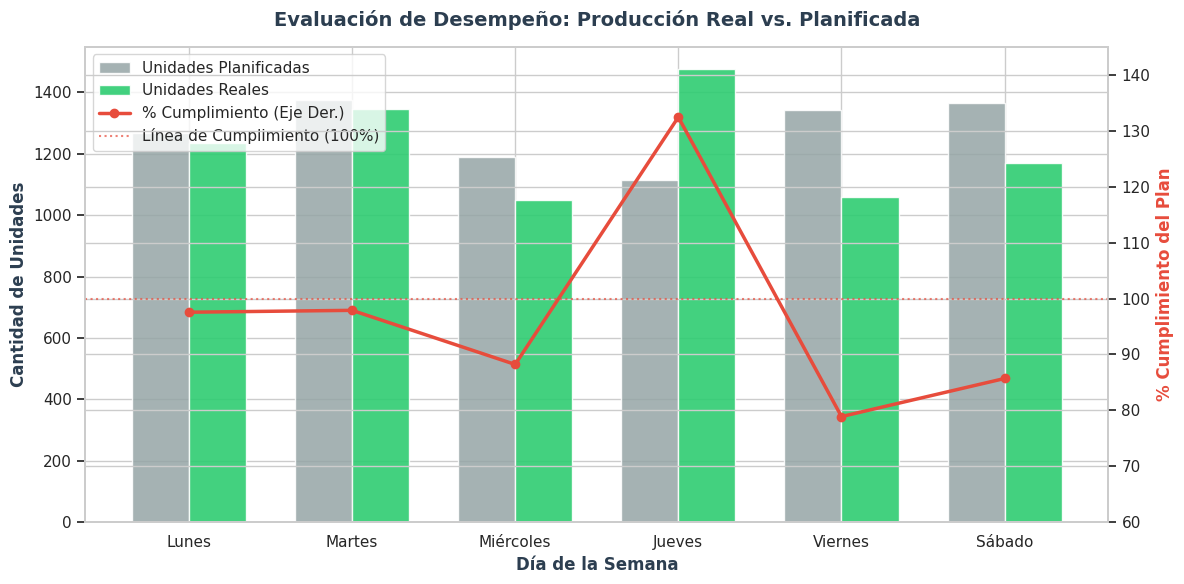

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(12, 6))

x = np.arange(len(df_kpis['Día']))
width = 0.35

# Gráfico de barras (Eje Izquierdo - Unidades)
bar_plan = ax1.bar(x - width/2, unidades_planificadas, width, label='Unidades Planificadas', color='#95a5a6', alpha=0.85)
bar_real = ax1.bar(x + width/2, unidades_producidas, width, label='Unidades Reales', color='#2ecc71', alpha=0.9)
ax1.set_ylabel('Cantidad de Unidades', fontsize=12, fontweight='bold', color='#2c3e50')
ax1.set_xlabel('Día de la Semana', fontsize=12, fontweight='bold', color='#2c3e50')
ax1.set_xticks(x)
ax1.set_xticklabels(df_kpis['Día'])
ax1.set_title('Evaluación de Desempeño: Producción Real vs. Planificada', fontsize=14, fontweight='bold', color='#2c3e50', pad=15)

# Gráfico de líneas (Eje Derecho - % Cumplimiento)
ax2 = ax1.twinx()
line_cumplimiento = ax2.plot(x, df_kpis['Cumplimiento Plan (%)'], color='#e74c3c', marker='o', linewidth=2.5, label='% Cumplimiento (Eje Der.)')
ax2.axhline(100, color='#e74c3c', linestyle=':', alpha=0.7, label='Línea de Cumplimiento (100%)')
ax2.set_ylabel('% Cumplimiento del Plan', fontsize=12, fontweight='bold', color='#e74c3c')
ax2.set_ylim(60, 145)

# Leyendas combinadas
lineas, etiquetas = ax1.get_legend_handles_labels()
lineas2, etiquetas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas + lineas2, etiquetas + etiquetas2, loc='upper left')

plt.tight_layout()
plt.show()